Titanic Dataset Loaded Successfully!
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0          

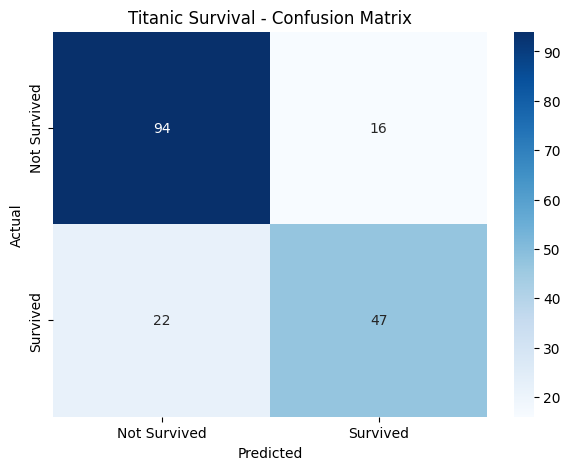


True Negative: 94
False Positive: 16
False Negative: 22
True Positive: 47

Day 39 Task Completed Successfully!


In [2]:

# DAY 39 - CONFUSION MATRIX
# TITANIC SURVIVAL PREDICTION

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

# 1. Load Titanic Dataset
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

print("Titanic Dataset Loaded Successfully!")
print(df.head())

# 2. Data Preprocessing
df = df[['Survived', 'Pclass', 'Sex', 'Age', 'Fare']].copy()

df['Age'] = df['Age'].fillna(df['Age'].median())
df['Fare'] = df['Fare'].fillna(df['Fare'].median())
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})

# 3. Features and Target
X = df[['Pclass', 'Sex', 'Age', 'Fare']]
y = df['Survived']

# 4. Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 5. Train Model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# 6. Predictions
y_pred = model.predict(X_test)

# 7. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:")
print(cm)

# 8. Accuracy
print("\nAccuracy:", accuracy_score(y_test, y_pred))

# 9. Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# 10. Visualize Confusion Matrix
plt.figure(figsize=(7,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Survived', 'Survived'],
            yticklabels=['Not Survived', 'Survived'])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Titanic Survival - Confusion Matrix")
plt.show()

# 11. TP, TN, FP, FN
tn, fp, fn, tp = cm.ravel()

print("\nTrue Negative:", tn)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Positive:", tp)

print("\nDay 39 Task Completed Successfully!")
